In [1]:
# ===============================
# 1) Imports & configuration
# ===============================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from pypfopt import (
    EfficientFrontier,
    risk_models,
    expected_returns,
    HRPOpt,
)

In [2]:
# -------------------------------
# User-adjustable parameters
# -------------------------------

start_date_text = "2020-01-01"
end_date_text = "2025-01-01"

assets_list = [
    "SPY",  # S&P 500
    "QQQ",  # Nasdaq 100
    "RSP",  # Equal-weight S&P
    "IEFA", # Developed ex-US
    "EEM",  # Emerging markets
    "AGG",  # Aggregate bond
    "TLT",  # Long bonds
    "USFR", # Floating rate Treasuries
    "HYG",  # High yield
    "DBC",  # Commodities
    "GLD",  # Gold
    "DBMF", # Managed futures
    "RPAR", # Risk parity
    "BTAL", # Long-short defensive
    "NTSX", # Leveraged 60/40
    "RSST", # Trend-following
]

benchmark_csv_path = "benchmark.csv"  # Bloomberg benchmark CSV
risk_free_rate_annual = 0.035
trading_days_per_year = 252

In [3]:
# ===============================
# 2) Data download & preprocessing
# ===============================

def port_data_load_prices_yf(assets_list, start_date_text, end_date_text):
    """
    Download adjusted daily close prices from Yahoo Finance for given tickers and dates.
    Cleans data by forward-filling missing values and removing incomplete columns.
    """
    data_all = yf.download(
        tickers=assets_list,
        start=start_date_text,
        end=end_date_text,
        auto_adjust=True,
        progress=False,
    )["Close"]
    data_all = data_all.dropna(how="all").ffill().dropna(axis=1, how="any")
    return data_all


def port_data_compute_returns(prices_frame):
    """
    Compute daily percentage returns from price data.
    Drops rows with missing values.
    """
    returns_frame = prices_frame.pct_change().dropna(how="any")
    return returns_frame

In [4]:
# ===============================
# 3) Helper functions (metrics)
# ===============================

def port_metrics_compute_portfolio_series(weights_series, returns_frame):
    """
    Compute portfolio daily returns as weighted sum of asset returns.
    Ensures weights align with return columns.
    """
    weights_series = weights_series.reindex(returns_frame.columns).fillna(0.0)
    portfolio_return_series = (returns_frame * weights_series).sum(axis=1)
    return portfolio_return_series


def port_metrics_expected_annual_return(portfolio_return_series, trading_days_per_year):
    """
    Compute annualized expected return from average daily return.
    """
    return float(portfolio_return_series.mean() * trading_days_per_year)


def port_metrics_volatility_daily(portfolio_return_series):
    """
    Compute daily portfolio volatility (standard deviation of returns).
    """
    return float(portfolio_return_series.std(ddof=0))


def port_metrics_volatility_annual(portfolio_return_series, trading_days_per_year):
    """
    Compute annualized volatility using sqrt(time) scaling.
    """
    return float(portfolio_return_series.std(ddof=0) * np.sqrt(trading_days_per_year))


def port_metrics_sharpe_ratio(portfolio_return_series, risk_free_rate_annual, trading_days_per_year):
    """
    Compute annualized Sharpe ratio (excess return / total volatility).
    """
    rf_daily = risk_free_rate_annual / trading_days_per_year
    excess_daily = portfolio_return_series - rf_daily
    avg_excess_daily = excess_daily.mean()
    std_daily = portfolio_return_series.std(ddof=0)
    if std_daily == 0:
        return np.nan
    return float((avg_excess_daily * trading_days_per_year) / (std_daily * np.sqrt(trading_days_per_year)))


def port_metrics_sortino_ratio(portfolio_return_series, risk_free_rate_annual, trading_days_per_year):
    """
    Compute annualized Sortino ratio (excess return / downside volatility).
    Downside deviation considers only negative excess returns.
    """
    rf_daily = risk_free_rate_annual / trading_days_per_year
    downside = np.minimum(0.0, portfolio_return_series - rf_daily)
    downside_std_daily = downside.std(ddof=0)
    if downside_std_daily == 0:
        return np.nan
    avg_excess_daily = (portfolio_return_series - rf_daily).mean()
    return float((avg_excess_daily * trading_days_per_year) / (downside_std_daily * np.sqrt(trading_days_per_year)))


def port_metrics_drawdown_max(portfolio_return_series): # <---- CHECK THIS, ADD HMW?
    """
    Compute maximum drawdown from cumulative portfolio wealth.
    """
    wealth = (1.0 + portfolio_return_series).cumprod()
    rolling_max = wealth.cummax()
    drawdown_series = wealth / rolling_max - 1.0
    return float(drawdown_series.min())


def port_metrics_tracking_error_and_ir(portfolio_return_series, benchmark_return_series, trading_days_per_year): # <---- CHECK THIS, SEPARATE?
    """
    Compute annualized tracking error and information ratio relative to benchmark.
    TE = std(active returns) * sqrt(252)
    IR = (portfolio_return - benchmark_return) / TE
    """
    active_daily = portfolio_return_series - benchmark_return_series
    te_annual = active_daily.std(ddof=0) * np.sqrt(trading_days_per_year)
    port_ann_return = portfolio_return_series.mean() * trading_days_per_year
    bench_ann_return = benchmark_return_series.mean() * trading_days_per_year
    info_ratio = np.nan if te_annual == 0 else ((port_ann_return - bench_ann_return) / te_annual)
    return float(te_annual), float(info_ratio)


def port_metrics_summarize(weights_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year):
    """
    Compute all main performance metrics for a portfolio:
    expected return, volatility, Sharpe, Sortino, max drawdown, TE, and IR.
    """
    port_series = port_metrics_compute_portfolio_series(weights_series, returns_frame)
    te_annual, info_ratio = port_metrics_tracking_error_and_ir(port_series, benchmark_return_series, trading_days_per_year)
    return {
        "expected_return_annual": port_metrics_expected_annual_return(port_series, trading_days_per_year),
        "volatility_daily": port_metrics_volatility_daily(port_series),
        "volatility_annual": port_metrics_volatility_annual(port_series, trading_days_per_year),
        "sharpe_ratio": port_metrics_sharpe_ratio(port_series, risk_free_rate_annual, trading_days_per_year),
        "sortino_ratio": port_metrics_sortino_ratio(port_series, risk_free_rate_annual, trading_days_per_year),
        "max_drawdown": port_metrics_drawdown_max(port_series),
        "tracking_error_annual": te_annual,
        "information_ratio": info_ratio,
    }


def port_utils_clean_weights(weights_dict):
    """
    Convert weight dictionary to sorted pandas Series and remove near-zero allocations.
    """
    series = pd.Series(weights_dict)
    series = series[series.abs() > 1e-6]
    return series.sort_values(ascending=False)

In [5]:
# ===============================
# 3.5) Benchmark loader (Bloomberg final)
# ===============================

def port_data_load_benchmark_csv(csv_path_text):
    """
    Load Bloomberg-style benchmark CSV.
    Header around row 7, columns ['Date', 'PX_LAST', 'CHG_PCT_1D'].
    'CHG_PCT_1D' is in percent → divide by 100.
    """
    print("\n--- Benchmark Loading ---")
    print(f"[INFO] Loading benchmark CSV from: {csv_path_text}")

    frame = pd.read_csv(csv_path_text, skiprows=6)
    print("[DEBUG] Raw columns read:", list(frame.columns))

    frame.columns = [str(c).strip().lower() for c in frame.columns]
    frame = frame.dropna(how="all")

    if "date" not in frame.columns:
        raise ValueError(f"[ERROR] 'Date' column not found. Columns: {frame.columns.tolist()}")

    frame["date"] = pd.to_datetime(frame["date"], dayfirst=True, errors="coerce")
    frame = frame.dropna(subset=["date"]).set_index("date").sort_index()

    if "chg_pct_1d" in frame.columns:
        returns = frame["chg_pct_1d"].astype(float).dropna() / 100.0
        print("[INFO] Using 'CHG_PCT_1D' as benchmark returns (converted % → decimals).")
    elif "px_last" in frame.columns:
        returns = frame["px_last"].astype(float).pct_change().dropna()
        print("[WARN] 'CHG_PCT_1D' missing; computed returns from 'PX_LAST'.")
    else:
        raise ValueError(f"[ERROR] No return column found in file: {csv_path_text}")

    returns.name = "benchmark_return"

    print(f"[INFO] Loaded {len(returns)} daily benchmark returns.")
    print("[DEBUG] First 5 rows:")
    print(returns.head())
    print("[DEBUG] Last 5 rows:")
    print(returns.tail())
    print("--- End Benchmark Loading ---\n")

    return returns

In [6]:
# ===============================
# 4) Benchmark import + alignment
# ===============================

# --- Load asset data first (this was missing) ---
prices_frame = port_data_load_prices_yf(assets_list, start_date_text, end_date_text)
returns_frame = port_data_compute_returns(prices_frame)

# --- Then load benchmark ---
benchmark_return_series = port_data_load_benchmark_csv(benchmark_csv_path)

# --- Align by common dates only ---
common_index = returns_frame.index.intersection(benchmark_return_series.index)
returns_frame = returns_frame.loc[common_index]
benchmark_return_series = benchmark_return_series.loc[common_index]

print(f"[INFO] Common dates: {len(common_index)}")
print(f"[INFO] Benchmark range: {benchmark_return_series.index.min().date()} → {benchmark_return_series.index.max().date()}")
print(f"[INFO] Asset range: {returns_frame.index.min().date()} → {returns_frame.index.max().date()}")

# --- Compute benchmark metrics itself ---
benchmark_metrics = {
    "expected_return_annual": port_metrics_expected_annual_return(benchmark_return_series, trading_days_per_year),
    "volatility_daily": port_metrics_volatility_daily(benchmark_return_series),
    "volatility_annual": port_metrics_volatility_annual(benchmark_return_series, trading_days_per_year),
    "sharpe_ratio": port_metrics_sharpe_ratio(benchmark_return_series, risk_free_rate_annual, trading_days_per_year),
    "sortino_ratio": port_metrics_sortino_ratio(benchmark_return_series, risk_free_rate_annual, trading_days_per_year),
    "max_drawdown": port_metrics_drawdown_max(benchmark_return_series),
}
print("\n=== Benchmark Metrics ===")
print(pd.DataFrame([benchmark_metrics], index=["benchmark"]))


--- Benchmark Loading ---
[INFO] Loading benchmark CSV from: benchmark.csv
[DEBUG] Raw columns read: ['Date', 'PX_LAST', 'CHG_PCT_1D']
[INFO] Using 'CHG_PCT_1D' as benchmark returns (converted % → decimals).
[INFO] Loaded 1298 daily benchmark returns.
[DEBUG] First 5 rows:
date
2020-10-09    0.006611
2020-10-12    0.007571
2020-10-13   -0.003421
2020-10-14   -0.001914
2020-10-15   -0.005196
Name: benchmark_return, dtype: float64
[DEBUG] Last 5 rows:
date
2025-10-02    0.000436
2025-10-03    0.001565
2025-10-06    0.000785
2025-10-07   -0.003301
2025-10-08    0.002503
Name: benchmark_return, dtype: float64
--- End Benchmark Loading ---

[INFO] Common dates: 1061
[INFO] Benchmark range: 2020-10-09 → 2024-12-31
[INFO] Asset range: 2020-10-09 → 2024-12-31

=== Benchmark Metrics ===
           expected_return_annual  volatility_daily  volatility_annual  \
benchmark                0.061209          0.006097           0.096787   

           sharpe_ratio  sortino_ratio  max_drawdown  
benchm

In [7]:
# ===============================
# 5) Portfolio Optimization
# ===============================

mu_series = expected_returns.mean_historical_return(prices_frame)
cov_matrix = risk_models.sample_cov(prices_frame)

ef_markowitz = EfficientFrontier(mu_series, cov_matrix, weight_bounds=(0.02, 0.15))
weights_markowitz_dict = ef_markowitz.max_sharpe(risk_free_rate=risk_free_rate_annual)
weights_markowitz_series = port_utils_clean_weights(ef_markowitz.clean_weights())

ef_minvar = EfficientFrontier(mu_series, cov_matrix, weight_bounds=(0.0, 0.15))
weights_minvar_dict = ef_minvar.min_volatility()
weights_minvar_series = port_utils_clean_weights(ef_minvar.clean_weights())

hrp_model = HRPOpt(returns_frame)
weights_riskparity_dict = hrp_model.optimize()
weights_riskparity_series = port_utils_clean_weights(weights_riskparity_dict)

weights_equal_series = pd.Series(1 / len(returns_frame.columns), index=returns_frame.columns)

def port_data_get_market_caps(tickers_list):
    caps_dict = {}
    for tkr in tickers_list:
        try:
            caps_dict[tkr] = yf.Ticker(tkr).info.get("marketCap", np.nan)
        except Exception:
            caps_dict[tkr] = np.nan
    caps_series = pd.Series(caps_dict).dropna()
    caps_series = caps_series / caps_series.sum()
    return caps_series

weights_value_series = port_data_get_market_caps(assets_list)
weights_value_series = weights_value_series.reindex(returns_frame.columns).fillna(0.0)

In [8]:
# ===============================
# 6) Portfolio Metrics
# ===============================

metrics_markowitz = port_metrics_summarize(weights_markowitz_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_minvar = port_metrics_summarize(weights_minvar_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_riskparity = port_metrics_summarize(weights_riskparity_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_equal = port_metrics_summarize(weights_equal_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_value = port_metrics_summarize(weights_value_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)

In [9]:
# ===============================
# 7) Present results
# ===============================

def port_table_build_weights(weights_series, portfolio_name_text):
    frame = weights_series.to_frame(name=portfolio_name_text)
    frame.index.name = "asset"
    return frame


def port_table_build_metrics(metrics_dict, portfolio_name_text):
    return pd.DataFrame([metrics_dict], index=[portfolio_name_text])


weights_table = (
    port_table_build_weights(weights_markowitz_series, "markowitz_max_sharpe")
    .join(port_table_build_weights(weights_minvar_series, "minimum_variance"), how="outer")
    .join(port_table_build_weights(weights_riskparity_series, "risk_parity_hrp"), how="outer")
    .join(port_table_build_weights(weights_equal_series, "equal_weighted"), how="outer")
    .join(port_table_build_weights(weights_value_series, "value_weighted"), how="outer")
).fillna(0.0)

metrics_table = pd.concat(
    [
        port_table_build_metrics(metrics_markowitz, "markowitz_max_sharpe"),
        port_table_build_metrics(metrics_minvar, "minimum_variance"),
        port_table_build_metrics(metrics_riskparity, "risk_parity_hrp"),
        port_table_build_metrics(metrics_equal, "equal_weighted"),
        port_table_build_metrics(metrics_value, "value_weighted"),
        port_table_build_metrics(benchmark_metrics, "benchmark"),
    ],
    axis=0,
)

pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

print("\n=== Portfolio Weights (sums ~1.00) ===")
print(weights_table.sort_index())

print("\n=== Metrics (annualized where applicable) ===")
print(metrics_table)


=== Portfolio Weights (sums ~1.00) ===
       markowitz_max_sharpe  minimum_variance  risk_parity_hrp  \
asset                                                            
AGG                  0.0200            0.1500           0.0017   
BTAL                 0.0200            0.1500           0.0008   
DBC                  0.0874            0.0458           0.0004   
DBMF                 0.1500            0.1500           0.0014   
EEM                  0.0200            0.0051           0.0004   
GLD                  0.1500            0.0409           0.0007   
HYG                  0.0200            0.1500           0.0021   
IEFA                 0.0200            0.0000           0.0002   
NTSX                 0.0200            0.0000           0.0002   
QQQ                  0.1500            0.0000           0.0001   
RPAR                 0.0200            0.0000           0.0004   
RSP                  0.0200            0.0588           0.0002   
SPY                  0.1500         

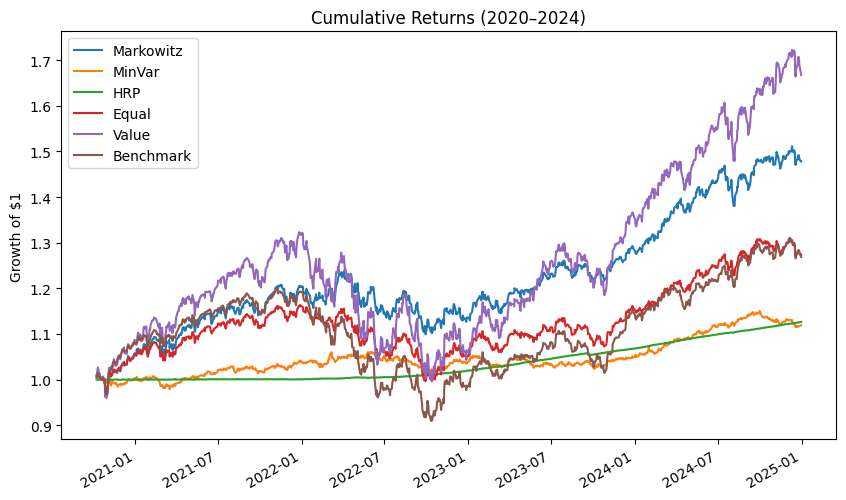

In [10]:
portfolios = {
    "Markowitz": port_metrics_compute_portfolio_series(weights_markowitz_series, returns_frame),
    "MinVar": port_metrics_compute_portfolio_series(weights_minvar_series, returns_frame),
    "HRP": port_metrics_compute_portfolio_series(weights_riskparity_series, returns_frame),
    "Equal": port_metrics_compute_portfolio_series(weights_equal_series, returns_frame),
    "Value": port_metrics_compute_portfolio_series(weights_value_series, returns_frame),
    "Benchmark": benchmark_return_series,
}

wealth = pd.DataFrame({k: (1 + v).cumprod() for k, v in portfolios.items()})
wealth.plot(figsize=(10, 6), title="Cumulative Returns (2020–2024)")
plt.ylabel("Growth of $1")
plt.show()